# Retail Sales Forecasting Using AR, ARIMA and SARIMA
##  Importing Required Libraries
This project uses time series forecasting techniques to
predict retail sales using historical sales data.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


##  Loading the Retail Sales Dataset

In [2]:
# Load the dataset

data = pd.read_csv("train.csv")

# Display the first five rows
data.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


##  Understanding the Dataset

In [3]:
print("Dataset Shape:", data.shape)

Dataset Shape: (913000, 4)


In [4]:
data['date'] = pd.to_datetime(data['date'])

print("Starting Date:", data['date'].min())
print("Ending Date:", data['date'].max())

Starting Date: 2013-01-01 00:00:00
Ending Date: 2017-12-31 00:00:00


## Data Preprocessing

### Aggregating Daily Sales into Monthly Sales

In [5]:
# Group daily sales into monthly sales

monthly_sales = (
    data.groupby(pd.Grouper(key='date', freq='MS'))['sales']
    .sum()
    .to_frame(name='Sales')
)

# Display first five months
print(monthly_sales.head())

             Sales
date              
2013-01-01  454904
2013-02-01  459417
2013-03-01  617382
2013-04-01  682274
2013-05-01  763242


In [6]:
print("Monthly Dataset Shape:", monthly_sales.shape)

print("\nStarting Month:", monthly_sales.index.min())
print("Ending Month:", monthly_sales.index.max())

print("\nMissing Values:")
print(monthly_sales.isnull().sum())

Monthly Dataset Shape: (60, 1)

Starting Month: 2013-01-01 00:00:00
Ending Month: 2017-12-01 00:00:00

Missing Values:
Sales    0
dtype: int64


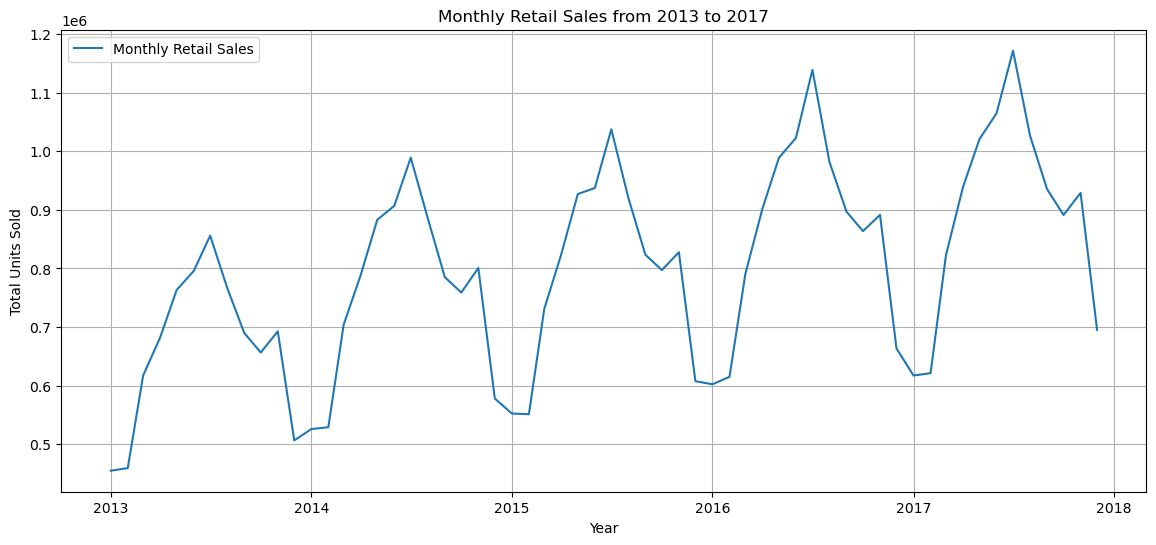

In [7]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales['Sales'],
    label='Monthly Retail Sales'
)

plt.title('Monthly Retail Sales from 2013 to 2017')
plt.xlabel('Year')
plt.ylabel('Total Units Sold')

plt.legend()
plt.grid(True)
plt.show()

In [8]:
monthly_sales.describe()

,Sales
count,6.000000e+01
mean,7.950752e+05
std,1.729018e+05
min,4.549040e+05
25%,6.617050e+05
50%,7.990180e+05
75%,9.220262e+05
max,1.171393e+06


### 5. Splitting Data into Training and Testing Sets

The monthly sales data is divided into training and testing datasets. The first 80% of the data is used to train the models, while the remaining 20% is used to test their forecasting performance.

In [9]:
# Split the data into training and testing sets

train = monthly_sales[
    monthly_sales.index < '2017-01-01'
]['Sales']

test = monthly_sales[
    monthly_sales.index >= '2017-01-01'
]['Sales']

print("Training Data:", len(train))
print("Testing Data:", len(test))

print("\nTraining Period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting Period:")
print(test.index.min(), "to", test.index.max())

Training Data: 48
Testing Data: 12

Training Period:
2013-01-01 00:00:00 to 2016-12-01 00:00:00

Testing Period:
2017-01-01 00:00:00 to 2017-12-01 00:00:00


##  Model 1 - Auto Regression (AR)

Auto Regression predicts future retail sales using
previous sales observations.

In [10]:
# Build Auto Regression model

ar_model = AutoReg(
    train,
    lags=12,
    old_names=False
)

# Train the model
ar_fitted = ar_model.fit()

# Display model summary
print(ar_fitted.summary())

                            AutoReg Model Results                             
Dep. Variable:                  Sales   No. Observations:                   48
Model:                    AutoReg(12)   Log Likelihood                -412.365
Method:               Conditional MLE   S.D. of innovations          22825.957
Date:                Tue, 17 Nov 2026   AIC                            852.731
Time:                        23:03:41   BIC                            874.900
Sample:                    01-01-2014   HQIC                           860.468
                         - 12-01-2016                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.672e+05   5.84e+04      4.571      0.000    1.53e+05    3.82e+05
Sales.L1       0.2119      0.094      2.260      0.024       0.028       0.396
Sales.L2      -0.1371      0.100     -1.376      0.1

In [11]:
# Generate predictions for the testing period

ar_predictions = ar_fitted.predict(
    start=len(train),
    end=len(train) + len(test) - 1,
    dynamic=False
)

# Assign testing dates
ar_predictions.index = test.index

print("Auto Regression Predictions:")
print(ar_predictions)

Auto Regression Predictions:
date
2017-01-01    6.161722e+05
2017-02-01    6.211033e+05
2017-03-01    8.151927e+05
2017-04-01    9.206918e+05
2017-05-01    1.028467e+06
2017-06-01    1.069896e+06
2017-07-01    1.198322e+06
2017-08-01    1.033858e+06
2017-09-01    9.377895e+05
2017-10-01    9.003518e+05
2017-11-01    9.242884e+05
2017-12-01    6.988126e+05
Freq: MS, dtype: float64


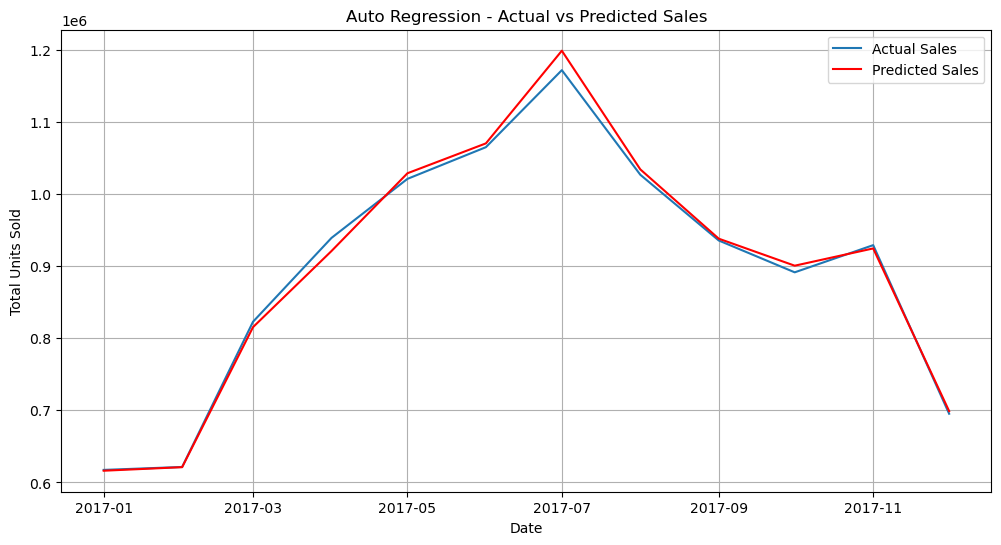

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(test, label='Actual Sales')
plt.plot(ar_predictions, color='red', label='Predicted Sales')

plt.title('Auto Regression - Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')

plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Calculate RMSE and MAPE

ar_rmse = np.sqrt(
    mean_squared_error(test, ar_predictions)
)

ar_mape = mean_absolute_percentage_error(
    test, ar_predictions
) * 100

print("Auto Regression Model Evaluation")
print("----------------------------------")
print("RMSE:", ar_rmse)
print("MAPE:", ar_mape, "%")

Auto Regression Model Evaluation
----------------------------------
RMSE: 10728.918836105191
MAPE: 0.8056972297313527 %


In [14]:
# Store AR model performance

results = pd.DataFrame({
    'Model': ['Auto Regression'],
    'RMSE': [ar_rmse],
    'MAPE': [ar_mape]
})

print(results)

             Model          RMSE      MAPE
0  Auto Regression  10728.918836  0.805697


##  Model 2 - ARIMA (AutoRegressive Integrated Moving Average)

In [15]:
# Find the best ARIMA parameters using AIC

import itertools

p_values = range(0, 7)
q_values = range(0, 1)
d = 0

best_aic = float('inf')
best_order = None

for p, q in itertools.product(p_values, q_values):
    try:
        model = ARIMA(train, order=(p, d, q))
        fitted_model = model.fit()

        if fitted_model.aic < best_aic:
            best_aic = fitted_model.aic
            best_order = (p, d, q)

    except Exception:
        continue

print("Best ARIMA Order:", best_order)
print("Best AIC:", best_aic)

Best ARIMA Order: (6, 0, 0)
Best AIC: 1226.1100313514635


In [16]:
# Build the ARIMA model

arima_model = ARIMA(
    train,
    order=best_order
)

# Fit the model
arima_fitted = arima_model.fit()

# Display model summary
print(arima_fitted.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(6, 0, 0)   Log Likelihood                -605.055
Date:                Tue, 17 Nov 2026   AIC                           1226.110
Time:                        23:03:42   BIC                           1241.080
Sample:                    01-01-2013   HQIC                          1231.767
                         - 12-01-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       7.702e+05   3.89e+04     19.783      0.000    6.94e+05    8.47e+05
ar.L1          1.1243      0.203      5.534      0.000       0.726       1.522
ar.L2         -0.3019      0.307     -0.982      0.3

In [17]:
# Predict sales for the testing period

arima_predictions = arima_fitted.forecast(
    steps=len(test)
)

# Assign testing dates
arima_predictions.index = test.index

print("ARIMA Predictions:")
print(arima_predictions)

ARIMA Predictions:
date
2017-01-01    622678.538254
2017-02-01    636171.084316
2017-03-01    706873.934012
2017-04-01    643921.431283
2017-05-01    742903.674569
2017-06-01    811142.837571
2017-07-01    872346.209075
2017-08-01    818893.019353
2017-09-01    860325.402163
2017-10-01    832476.862897
2017-11-01    805972.146675
2017-12-01    727084.780758
Freq: MS, Name: predicted_mean, dtype: float64


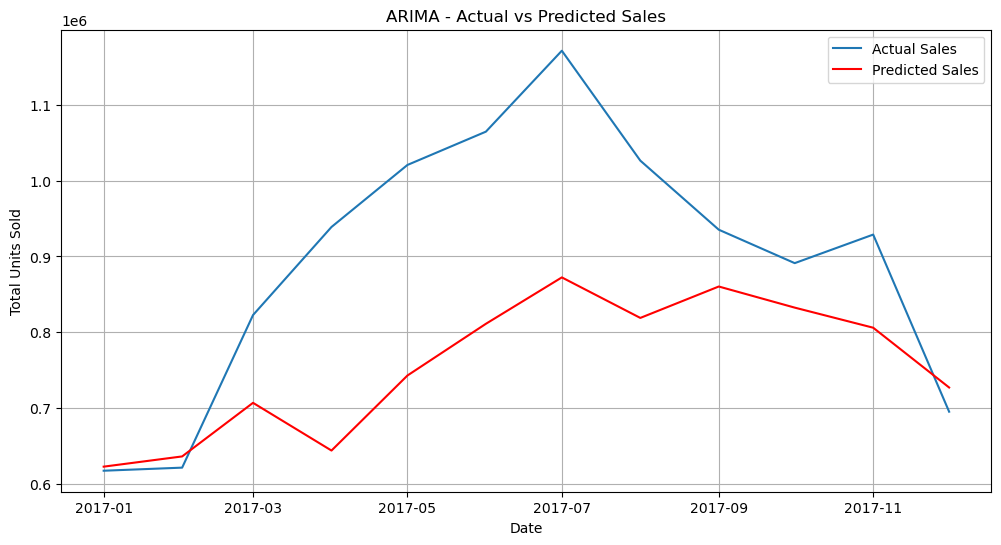

In [18]:
plt.figure(figsize=(12, 6))

plt.plot(test, label='Actual Sales')
plt.plot(arima_predictions, color='red', label='Predicted Sales')

plt.title('ARIMA - Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')

plt.legend()
plt.grid(True)
plt.show()

In [19]:
# Calculate evaluation metrics

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_predictions)
)

arima_mape = mean_absolute_percentage_error(
    test, arima_predictions
) * 100

print("ARIMA Model Evaluation")
print("-------------------------")
print("Best Order:", best_order)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape, "%")

ARIMA Model Evaluation
-------------------------
Best Order: (6, 0, 0)
RMSE: 182511.34985159186
MAPE: 14.82748512290884 %


In [20]:
# Add ARIMA results to existing results table

results.loc[len(results)] = [
    'ARIMA',
    arima_rmse,
    arima_mape
]

print(results)

             Model           RMSE       MAPE
0  Auto Regression   10728.918836   0.805697
1            ARIMA  182511.349852  14.827485


##  Model 3 - SARIMA
### Seasonal AutoRegressive Integrated Moving Average

In [21]:
# Define parameter combinations
p = range(0, 2)
d = range(0, 2)
q = range(0, 2)

seasonal_period = 12

# Generate all possible combinations
pdq = list(itertools.product(p, d, q))

seasonal_pdq = [
    (x[0], x[1], x[2], seasonal_period)
    for x in pdq
]

best_sarima_aic = float('inf')
best_sarima_order = None
best_seasonal_order = None

# Search for the best SARIMA model
for order in pdq:
    for seasonal in seasonal_pdq:
        try:
            model = SARIMAX(
                train,
                order=order,
                seasonal_order=seasonal,
                enforce_invertibility=False,
                enforce_stationarity=False
            )

            fitted = model.fit(disp=False)

            if fitted.aic < best_sarima_aic:
                best_sarima_aic = fitted.aic
                best_sarima_order = order
                best_seasonal_order = seasonal

        except Exception:
            continue

print("Best SARIMA Order:", best_sarima_order)
print("Best Seasonal Order:", best_seasonal_order)
print("Best AIC:", best_sarima_aic)

Best SARIMA Order: (0, 1, 1)
Best Seasonal Order: (0, 1, 1, 12)
Best AIC: 467.77716968852894


In [22]:
# Build SARIMA model

sarima_model = SARIMAX(
    train,
    order=best_sarima_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the model
sarima_fitted = sarima_model.fit(disp=False)

# Display model summary
print(sarima_fitted.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   48
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -230.889
Date:                            Tue, 17 Nov 2026   AIC                            467.777
Time:                                    23:03:53   BIC                            470.911
Sample:                                01-01-2013   HQIC                           468.457
                                     - 12-01-2016                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5314      0.191     -2.781      0.005      -0.906      -0.157
ma.S.L12      -0.1025      0.142   

In [23]:
# Forecast the next 12 months

sarima_predictions = sarima_fitted.forecast(
    steps=len(test)
)

sarima_predictions.index = test.index

print("SARIMA Predictions:")
print(sarima_predictions)

SARIMA Predictions:
date
2017-01-01    6.635826e+05
2017-02-01    6.747400e+05
2017-03-01    8.509618e+05
2017-04-01    9.601090e+05
2017-05-01    1.048382e+06
2017-06-01    1.080041e+06
2017-07-01    1.194246e+06
2017-08-01    1.041319e+06
2017-09-01    9.553822e+05
2017-10-01    9.229120e+05
2017-11-01    9.510982e+05
2017-12-01    7.239097e+05
Freq: MS, Name: predicted_mean, dtype: float64


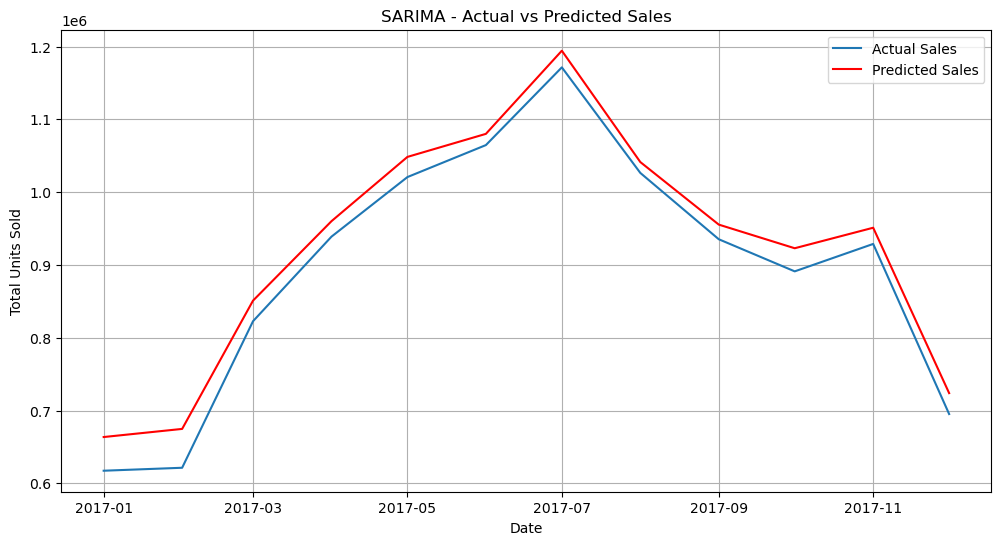

In [24]:
plt.figure(figsize=(12, 6))

plt.plot(test, label='Actual Sales')
plt.plot(sarima_predictions, color='red', label='Predicted Sales')

plt.title('SARIMA - Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')

plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Calculate evaluation metrics

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_predictions)
)

sarima_mape = mean_absolute_percentage_error(
    test, sarima_predictions
) * 100

print("SARIMA Model Evaluation")
print("-------------------------")
print("RMSE:", sarima_rmse)
print("MAPE:", sarima_mape, "%")

SARIMA Model Evaluation
-------------------------
RMSE: 29897.10079347456
MAPE: 3.4665900077778318 %


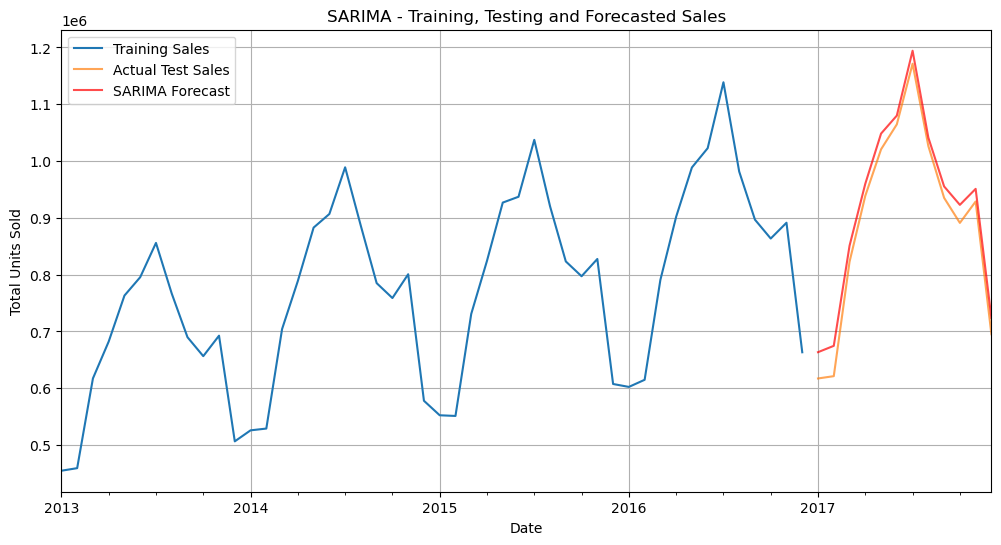

In [26]:
# Plotting the train, test and forecasted sales

plt.figure(figsize=(12, 6))

axis = train.plot(label='Training Sales')

test.plot(ax=axis, label='Actual Test Sales', alpha=0.7)

sarima_predictions.plot(
    ax=axis,
    label='SARIMA Forecast',
    alpha=0.7,
    color='red'
)

axis.set_title('SARIMA - Training, Testing and Forecasted Sales')
axis.set_xlabel('Date')
axis.set_ylabel('Total Units Sold')

plt.legend(loc='best')
plt.grid(True)
plt.show()
plt.close()

In [27]:
# Add SARIMA results to comparison table

results.loc[len(results)] = [
    'SARIMA',
    sarima_rmse,
    sarima_mape
]

print(results)

             Model           RMSE       MAPE
0  Auto Regression   10728.918836   0.805697
1            ARIMA  182511.349852  14.827485
2           SARIMA   29897.100793   3.466590


In [28]:
# Final comparison of all models

results = results[['Model', 'RMSE', 'MAPE']]

results

,Model,RMSE,MAPE
0,Auto Regression,10728.918836,0.805697
1,ARIMA,182511.349852,14.827485
2,SARIMA,29897.100793,3.466590
